# Titanic Survival Prediction

## Introduction

The Titanic Survival Prediction project uses machine learning to predict whether a passenger survived the Titanic disaster based on passenger information.

In this project, the Titanic dataset from Kaggle is analyzed and cleaned using Pandas. A Logistic Regression model from Scikit-learn is then trained to predict passenger survival.

The project also includes data visualization and model evaluation to understand the patterns in the dataset and measure the performance of the machine learning model.

## Objective

The main objectives of this project are:

1. Load and explore the Titanic dataset.
2. Clean and preprocess the dataset.
3. Select relevant features for prediction.
4. Train a Logistic Regression model.
5. Evaluate the model using accuracy, precision, recall, F1-score, and confusion matrix.
6. Visualize important patterns in passenger survival.
7. Use the trained model to predict the survival of a new passenger.

## Technologies Used

- **Python** – Programming language
- **Pandas** – Data loading, manipulation, and cleaning
- **Matplotlib** – Data visualization
- **Scikit-learn** – Machine learning and model evaluation
- **Google Colab** – Development environment
- **Kaggle Titanic Dataset** – Dataset used for the project
- **Logistic Regression** – Machine learning algorithm

# Load the Training Dataset
The training dataset is used to explore passenger information and train the model.

In [1]:
import pandas as pd

# Load the Titanic dataset
df = pd.read_csv('/content/train.csv')

# Display the first 5 rows
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Explore the Dataset
Check the columns, data types, and basic statistics before cleaning.

In [2]:
# Check the size of the dataset
print("Dataset Shape:", df.shape)

# Check the column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check basic information about the dataset
print("\nDataset Information:")
df.info()

Dataset Shape: (891, 12)

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


# Check Missing Values
Missing values can affect model training, so identify them before preprocessing.

In [3]:
# Check the number of missing values in each column
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [4]:
# Display statistical summary of numerical columns
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


# Visualize the Survival Distribution
This chart shows how many training passengers survived and did not survive.

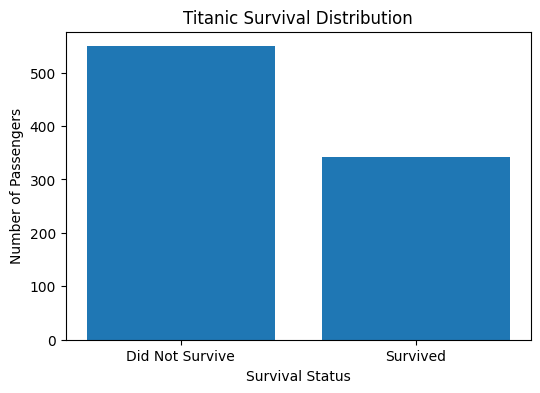

In [5]:
import matplotlib.pyplot as plt

# Count the number of passengers who survived and did not survive
survival_counts = df['Survived'].value_counts()

# Create a bar chart
plt.figure(figsize=(6, 4))
plt.bar(['Did Not Survive', 'Survived'], survival_counts)
plt.title('Titanic Survival Distribution')
plt.xlabel('Survival Status')
plt.ylabel('Number of Passengers')
plt.show()

# Clean and prepare the Training Data

In [6]:
# Remove the Cabin column because it contains many missing values
df = df.drop('Cabin', axis=1)

# Fill missing Age values with the median age
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill missing Embarked values with the most common value
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Check missing values again
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [7]:
#Remove unnecessary columns

df = df.drop(['PassengerId', 'Name', 'Ticket'], axis=1)

# Display the remaining columns
print("Remaining columns:")
print(df.columns.tolist())

Remaining columns:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


In [8]:
# Convert categorical variables into numerical variables

df = pd.get_dummies(df, columns=['Sex', 'Embarked'], drop_first=True)

# Display the first 5 rows
df.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,35.0,0,0,8.0500,True,False,True


# Select Features and Target
`X` contains the input features; `y` contains the label the model learns to predict.

In [9]:
# Feature Selection

# Features used to predict survival
X = df.drop('Survived', axis=1)

# Target variable
y = df['Survived']

print("Features (X):")
print(X.columns.tolist())

print("\nTarget (y):")
print(y.name)

Features (X):
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']

Target (y):
Survived


# Split the Data
Hold out 20% of the labeled data for evaluation. The model will train on the other 80%.

In [10]:
# Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (712, 8)
Testing data: (179, 8)


# Train the Logistic Regression Model
Logistic Regression is a classification algorithm that estimates the probability of a passenger belonging to each class.

In [11]:
# Train Logistic Regression model

from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


# Generate Predictions for the Held-Out Data

In [12]:
# Make predictions on the test data

y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:20])

Predictions:
[0 0 0 1 1 1 1 0 1 1 0 0 0 0 0 1 0 1 0 0]


##Evaluate Model Performance
Accuracy is the proportion of predictions that match the known labels in the held-out data. The classification report gives additional metrics.

In [13]:
# Evaluate model accuracy

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 81.01%


# Confusion Matrix
Rows represent the actual labels; columns represent the model's predicted labels.

In [14]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[90 15]
 [19 55]]


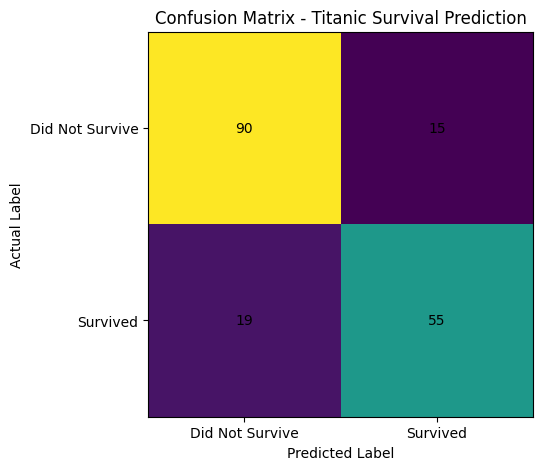

In [15]:
# Visualize the Confusion Matrix

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title('Confusion Matrix - Titanic Survival Prediction')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.xticks([0, 1], ['Did Not Survive', 'Survived'])
plt.yticks([0, 1], ['Did Not Survive', 'Survived'])

# Display values inside the matrix
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.show()

#Explore Survival Patterns
These charts describe patterns in the labeled training dataset. They show associations and do not, by themselves, prove causation

/tmp/ipykernel_1328/2898797591.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  [gender_survival[0], gender_survival[1]]


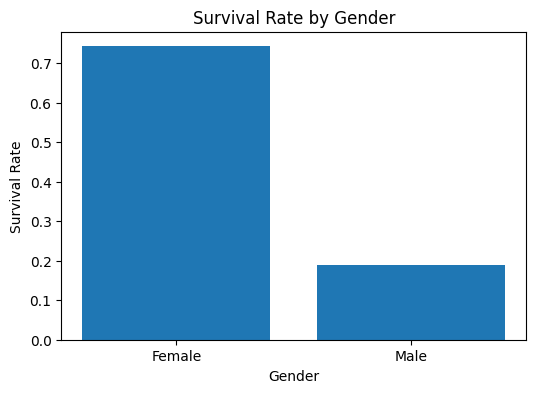

In [16]:
# Survival by Gender

gender_survival = df.groupby('Sex_male')['Survived'].mean()

plt.figure(figsize=(6, 4))

plt.bar(
    ['Female', 'Male'],
    [gender_survival[0], gender_survival[1]]
)

plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate')

plt.show()

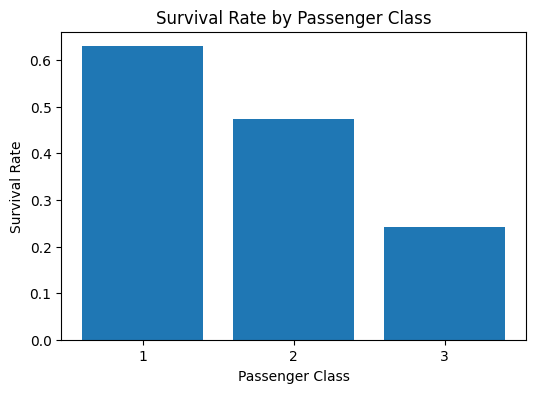

In [17]:
#Survival by Passenger Class

class_survival = df.groupby('Pclass')['Survived'].mean()

plt.figure(figsize=(6, 4))

plt.bar(
    class_survival.index.astype(str),
    class_survival.values
)

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')

plt.show()

In [18]:
# Step 21: Classification Report

from sklearn.metrics import classification_report

report = classification_report(y_test, y_pred)

print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



# Predict for an Example Passenger
The example below represents a first-class, 25-year-old female passenger, travelling without siblings/spouses or parents/children, with a fare of 80 and an embarkation port represented by `Embarked_S = 1`.

In [19]:
# Prediction for a New Passenger

# Example passenger details
new_passenger = pd.DataFrame({
    'Pclass': [1],
    'Age': [25],
    'SibSp': [0],
    'Parch': [0],
    'Fare': [80],
    'Sex_male': [0],
    'Embarked_Q': [0],
    'Embarked_S': [1]
})

# Make prediction
prediction = model.predict(new_passenger)

if prediction[0] == 1:
    print("Prediction: Passenger is likely to SURVIVE.")
else:
    print("Prediction: Passenger is likely to NOT SURVIVE.")

Prediction: Passenger is likely to SURVIVE.


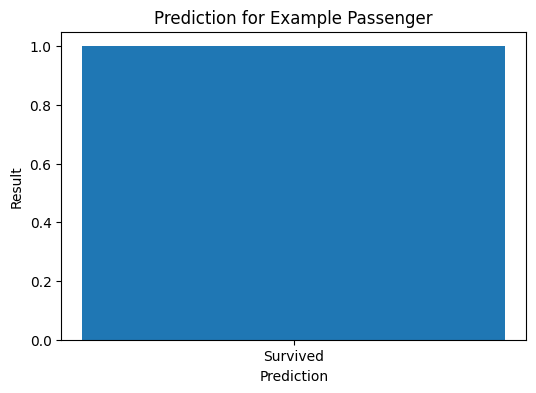

In [20]:
# Visualize Prediction

prediction_label = ['Survived' if prediction[0] == 1 else 'Did Not Survive']

plt.figure(figsize=(6, 4))

plt.bar(prediction_label, [1])

plt.title('Prediction for Example Passenger')
plt.xlabel('Prediction')
plt.ylabel('Result')

plt.show()

# Load and Inspect the Separate Test Dataset

The separate `test.csv` file has passenger details but no `Survived` labels. Therefore, we can generate predictions for it, but we cannot calculate accuracy for these rows unless the true labels are provided separately.

In [21]:
# Load the Test Dataset

test_df = pd.read_csv('/content/test.csv')

print("Test Dataset Shape:", test_df.shape)

print("\nFirst 5 Rows:")
test_df.head()

Test Dataset Shape: (418, 11)

First 5 Rows:


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


# Explore the Test Dataset

In [22]:
# Explore the Test Dataset

print("Missing Values in Test Dataset:")
print(test_df.isnull().sum())

print("\nTest Dataset Columns:")
print(test_df.columns.tolist())

Missing Values in Test Dataset:
PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

Test Dataset Columns:
['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


# Prepare the Test Dataset
Apply compatible cleaning and encoding, then align its columns with the features used to train the model.

In [23]:
# Step 26: Clean and Prepare Test Data

test_ids = test_df['PassengerId'].copy()

test_df = test_df.drop(
    ['PassengerId', 'Name', 'Ticket', 'Cabin'],
    axis=1
)

test_df['Age'] = test_df['Age'].fillna(
    test_df['Age'].median()
)

test_df['Fare'] = test_df['Fare'].fillna(
    test_df['Fare'].median()
)

test_df['Embarked'] = test_df['Embarked'].fillna(
    test_df['Embarked'].mode()[0]
)

test_df = pd.get_dummies(
    test_df,
    columns=['Sex', 'Embarked'],
    drop_first=True
)

# Ensure test features match the model's training features
test_df = test_df.reindex(
    columns=X.columns,
    fill_value=0
)

print("Prepared Test Dataset Shape:", test_df.shape)
print("Test features match training features:",
      list(test_df.columns) == list(X.columns))

Prepared Test Dataset Shape: (418, 8)
Test features match training features: True


# Predict Test Passenger Outcomes

In [25]:
# Predict Survival for Test Passengers

test_predictions = model.predict(test_df)

print("Predictions generated successfully!")
print("Total passengers:", len(test_predictions))
print("Predicted survivors:", (test_predictions == 1).sum())
print("Predicted non-survivors:", (test_predictions == 0).sum())

Predictions generated successfully!
Total passengers: 418
Predicted survivors: 157
Predicted non-survivors: 261


In [26]:
# Create Prediction Results

results = pd.DataFrame({
    'PassengerId': test_ids,
    'Predicted_Survived': test_predictions
})

results['Predicted_Status'] = results['Predicted_Survived'].map({
    0: 'Did Not Survive',
    1: 'Survived'
})

print("Prediction Results:")
results.head(10)

Prediction Results:


,PassengerId,Predicted_Survived,Predicted_Status
0,892,0,Did Not Survive
1,893,0,Did Not Survive
2,894,0,Did Not Survive
3,895,0,Did Not Survive
4,896,1,Survived
5,897,0,Did Not Survive
6,898,1,Survived
7,899,0,Did Not Survive
8,900,1,Survived
9,901,0,Did Not Survive


In [27]:
# Save Predictions to CSV

results.to_csv(
    '/content/Titanic_Test_Predictions.csv',
    index=False
)

print("Prediction file saved successfully!")

Prediction file saved successfully!


In [28]:
# Final Prediction Check

print("Total predictions:", len(results))
print("Missing predictions:", results['Predicted_Survived'].isnull().sum())
print("\nPrediction counts:")
print(results['Predicted_Status'].value_counts())

print("\nFirst 5 prediction results:")
display(results.head())

Total predictions: 418
Missing predictions: 0

Prediction counts:
Predicted_Status
Did Not Survive    261
Survived           157
Name: count, dtype: int64

First 5 prediction results:


,PassengerId,Predicted_Survived,Predicted_Status
0,892,0,Did Not Survive
1,893,0,Did Not Survive
2,894,0,Did Not Survive
3,895,0,Did Not Survive
4,896,1,Survived


## Conclusion

In this project, we developed a Titanic Survival Prediction model using Logistic Regression.

The Titanic dataset was loaded and analyzed using Pandas. Missing values were handled, unnecessary columns were removed, and categorical variables were converted into numerical form using one-hot encoding.

Important features such as passenger class, age, gender, number of siblings/spouses, parents/children, fare, and port of embarkation were used for prediction.

The dataset was divided into training and testing sets, and a Logistic Regression model was trained using Scikit-learn.

The model was evaluated using accuracy, confusion matrix, precision, recall, and F1-score. Additional visualizations were also created to understand survival patterns based on gender and passenger class.

Finally, the trained model was used to predict the survival of a new example passenger.

Overall, this project helped demonstrate the complete basic machine learning workflow, including data loading, data cleaning, feature selection, model training, evaluation, visualization, and prediction.

The model achieved **81.01% accuracy in the previously recorded run**. Your result may differ slightly if the data split or preprocessing changes. Accuracy on the held-out training data does not guarantee the same performance on unseen data.